In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


# 01. Load and clean the data

## What this notebook does, in plain words

A shop sells things. Each row in the raw file is one line on one receipt. This notebook loads those lines, counts what is messy, and cleans the file step by step. Cleaning matters because messy rows can quietly change every later answer.

## The dataset, stated plainly

The source is the UCI Machine Learning Repository, Online Retail II, dataset 502, by Daqing Chen (2012). It covers a UK based online retailer that mainly sells unique gift ware, and many of its customers are wholesalers. The full UCI file covers 1 December 2009 to 9 December 2011 and has 1,067,371 rows. This build uses the December 2010 to December 2011 slice, served as a CSV mirror, with 541,909 rows. That slice is the part most public RFM tutorials use. The difference is stated here so no one mistakes this slice for the full file.

## Cleaning rules, in order

1. Drop cancelled invoices. A cancelled invoice number starts with the letter C.
2. Drop rows with quantity at or below zero, or unit price at or below zero.
3. Drop rows with no CustomerID. Customer analysis needs a customer.
4. Add Revenue for each line: Quantity times UnitPrice, in pounds sterling.

## What to watch for

Rows with no CustomerID are a large group, not a small typo. They are counted below, not hidden. December 2011 is a partial month, because the data stop on 9 December 2011. Later notebooks flag that month instead of treating it as a full month.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams['figure.dpi'] = 120
ROOT = Path('..').resolve()
CHARTS = ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)
DATA = ROOT / 'data' / 'processed'
RAW = ROOT / 'data' / 'raw' / 'online_retail.csv'
print('Charts folder:', CHARTS)
print('Data folder:', DATA)


Charts folder: /home/hatch/workspace/repo-builds/datanalytics-project/charts
Data folder: /home/hatch/workspace/repo-builds/datanalytics-project/data/processed


In [3]:
df = pd.read_csv(RAW, encoding='utf-8')
print('Raw shape:', df.shape)
print(df.dtypes)
print(df.head(3).to_string())
print('Date range in raw text:', df['InvoiceDate'].min(), 'to', df['InvoiceDate'].max())
print('Countries in raw file:', df['Country'].nunique())
print('Missing values per column:')
print(df.isna().sum().to_string())

Raw shape: (541909, 8)
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object
  InvoiceNo StockCode                         Description  Quantity     InvoiceDate  UnitPrice  CustomerID         Country
0    536365    85123A  WHITE HANGING HEART T-LIGHT HOLDER         6  12/1/2010 8:26       2.55     17850.0  United Kingdom
1    536365     71053                 WHITE METAL LANTERN         6  12/1/2010 8:26       3.39     17850.0  United Kingdom
2    536365    84406B      CREAM CUPID HEARTS COAT HANGER         8  12/1/2010 8:26       2.75     17850.0  United Kingdom
Date range in raw text: 1/10/2011 10:04 to 9/9/2011 9:52
Countries in raw file: 38
Missing values per column:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0


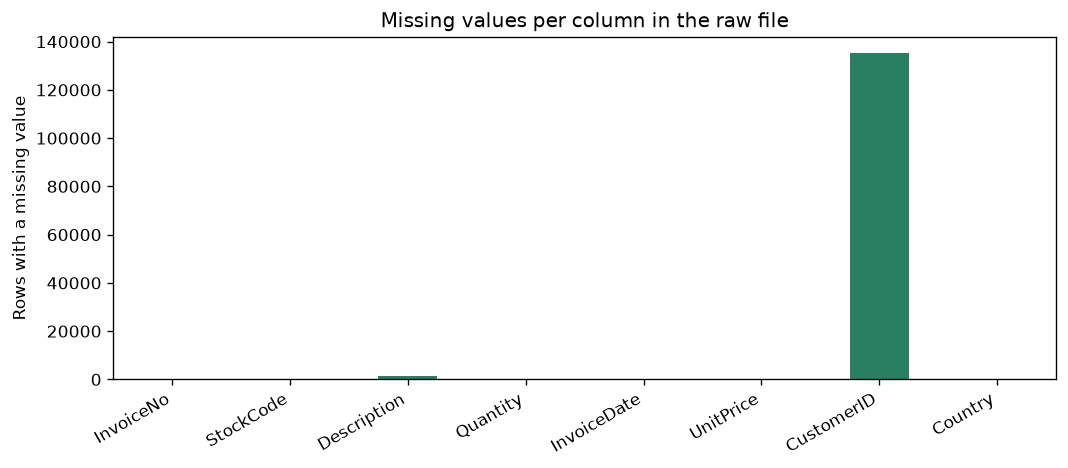

Largest gap: CustomerID is missing in 135080 raw rows.


In [4]:
missing = df.isna().sum()
fig, ax = plt.subplots(figsize=(9, 4))
missing.plot(kind='bar', ax=ax, color='#2a7f62')
ax.set_title('Missing values per column in the raw file')
ax.set_ylabel('Rows with a missing value')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(CHARTS / '01_missing_values.png')
plt.show()
print('Largest gap: CustomerID is missing in', int(missing['CustomerID']), 'raw rows.')

In [5]:
n_raw = len(df)
cancelled = int(df['InvoiceNo'].astype(str).str.startswith('C').sum())
d = df[~df['InvoiceNo'].astype(str).str.startswith('C')].copy()
d = d[(d['Quantity'] > 0) & (d['UnitPrice'] > 0)]
missing_after = int(d['CustomerID'].isna().sum())
d = d.dropna(subset=['CustomerID']).copy()
d['InvoiceDate'] = pd.to_datetime(d['InvoiceDate'])
d['Revenue'] = d['Quantity'] * d['UnitPrice']
print('Raw rows:', n_raw)
print('Cancelled rows removed:', cancelled)
print('Missing CustomerID rows removed at the customer step:', missing_after)
print('Clean rows kept:', len(d))
print('Clean revenue, pounds:', round(d['Revenue'].sum(), 2))
print('Clean customers:', d['CustomerID'].nunique())
print('Clean invoices:', d['InvoiceNo'].nunique())
print('Clean date range:', d['InvoiceDate'].min(), 'to', d['InvoiceDate'].max())
d.to_csv(DATA / 'clean_transactions.csv', index=False)

Raw rows: 541909
Cancelled rows removed: 9288
Missing CustomerID rows removed at the customer step: 132220
Clean rows kept: 397884
Clean revenue, pounds: 8911407.9
Clean customers: 4338
Clean invoices: 18532
Clean date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


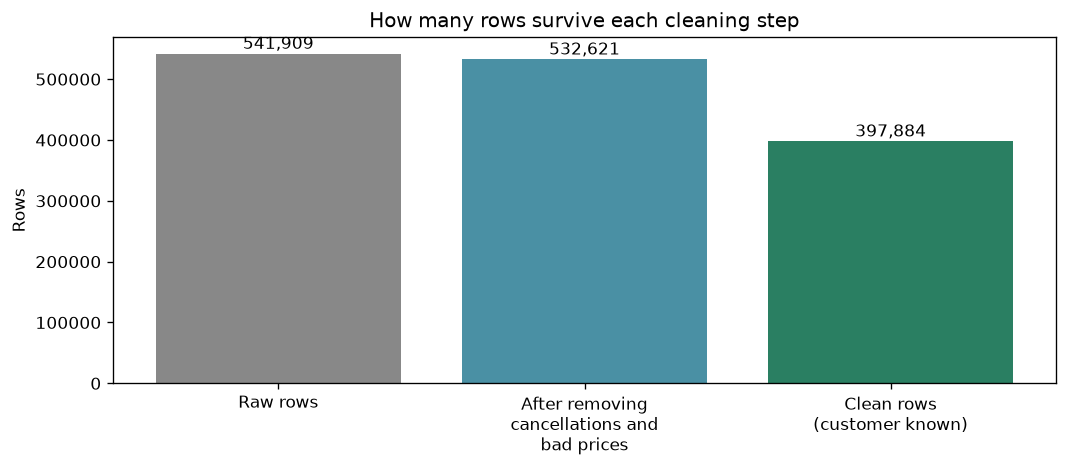

In [6]:
labels = ['Raw rows', 'After removing\ncancellations and\nbad prices', 'Clean rows\n(customer known)']
vals = [n_raw, n_raw - cancelled, len(d)]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(labels, vals, color=['#888888', '#4a90a4', '#2a7f62'])
ax.set_title('How many rows survive each cleaning step')
ax.set_ylabel('Rows')
for x, v in enumerate(vals):
    ax.text(x, v + 8000, f'{v:,}', ha='center')
plt.tight_layout()
plt.savefig(CHARTS / '02_cleaning_funnel.png')
plt.show()

## What we learned

The clean file has 397,884 rows, 4,338 customers, and 18,532 invoices, with revenue of 8,911,407.90 pounds. The biggest loss is rows with no customer, which is normal for this public file, because guest or manual lines carry no CustomerID. Those rows cannot be used for customer segments, so they are left out of RFM work, and that limit is stated again in notebook 04.

Next: notebook 02 looks at sales over time.